<a href="https://colab.research.google.com/github/Raj-18-45/Machine-Learning/blob/main/Unsupervised%20Learning/KMeans_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Description:

This experiment implements the K-Means Clustering algorithm using the Mall Customers dataset to group customers based on their annual income and spending score. The dataset is loaded and explored, and the optimal number of clusters is determined using the Elbow Method. K-Means is then applied to create five clusters. Finally, the cluster labels, centroids, and number of customers in each cluster are displayed, and the customer segments are visualized using a scatter plot.

In [1]:
#Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
#Load and Explore Dataset
df = pd.read_csv('/10.Mall_Customers.csv')

print(df.head())
print("Shape:", df.shape)
print(df.isnull().sum())

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Shape: (200, 5)
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [3]:
#Select Features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

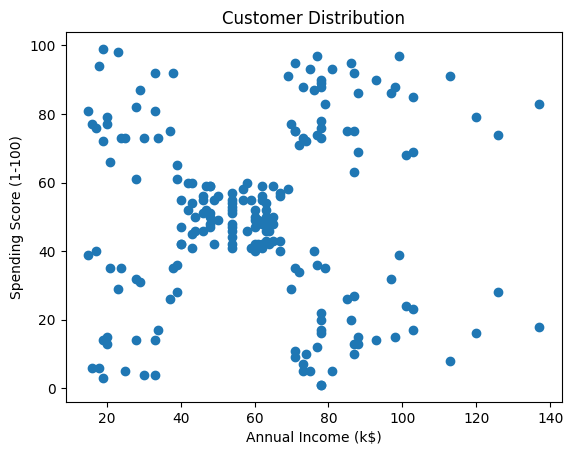

In [4]:
#Visualize Original Data
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Distribution')
plt.show()

In [5]:
#Find Optimal K Using Elbow Method
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

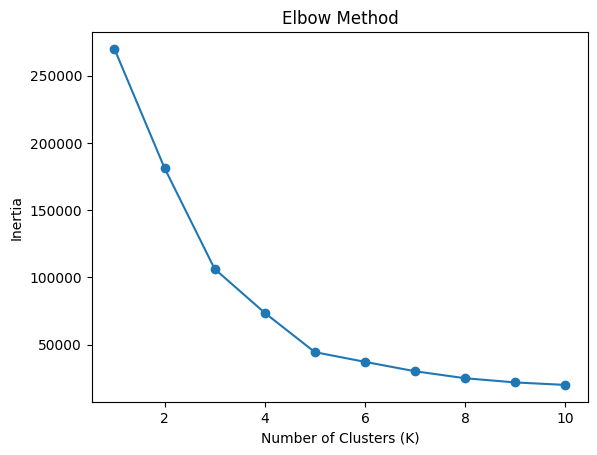

In [6]:
#Plot Elbow Curve
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [7]:
#Create and Train the K-Means Model
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans.fit(X)

KMeans(n_clusters=5, n_init=10, random_state=42)

In [8]:
# Get and Add Cluster Labels
labels = kmeans.labels_
df['Cluster'] = labels

In [9]:
#Display Cluster Centers
centers = kmeans.cluster_centers_

print(pd.DataFrame(centers, columns=[
    'Annual Income (k$)', 'Spending Score (1-100)'
]))

   Annual Income (k$)  Spending Score (1-100)
0           55.296296               49.518519
1           86.538462               82.128205
2           25.727273               79.363636
3           88.200000               17.114286
4           26.304348               20.913043


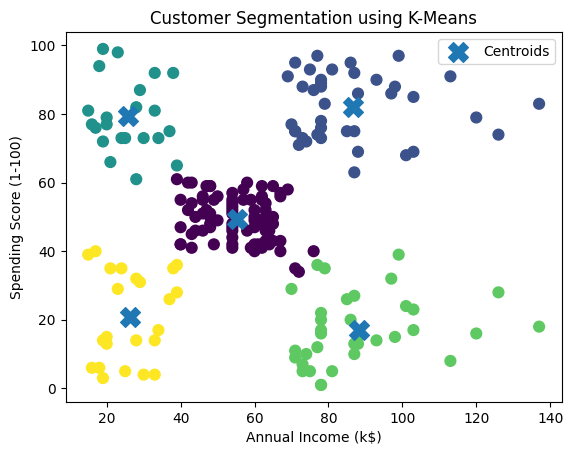

In [10]:
#Visualize Customer Segments
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels, s=60)

plt.scatter(centers[:, 0], centers[:, 1], s=200, marker='X', label='Centroids')

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segmentation using K-Means')
plt.legend()
plt.show()